# VogueMind — Préparation et exploration des données pour le système de recommandation

Travail de Safae benhaddou

## 1. Préparation de l’environnement et accès aux données

In [1]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 100)

print("Pandas :", pd.__version__)
print("NumPy :", np.__version__)

Pandas : 2.3.3
NumPy : 2.3.5


## 2. Chargement des jeux de données

In [2]:
DATA_DIR = Path("../data")  # à modifier si nécessaire
OUTPUT_DIR = DATA_DIR / "processed"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FILES = {
    "articles": DATA_DIR / "articles.csv",
    "customers": DATA_DIR / "customers.csv",
    "transactions": DATA_DIR / "transactions_train.csv"
}

for name, path in FILES.items():
    print(name, ":", path.resolve(), "| existe :", path.exists())

missing = [str(p) for p in FILES.values() if not p.exists()]
if missing:
    raise FileNotFoundError(
        "Fichier(s) manquant(s). Vérifie DATA_DIR et les noms :\n" + "\n".join(missing)
    )

articles : C:\Users\CYBORG\VogueMind\data\articles.csv | existe : True
customers : C:\Users\CYBORG\VogueMind\data\customers.csv | existe : True
transactions : C:\Users\CYBORG\VogueMind\data\transactions_train.csv | existe : True


## 3. Exploration de la structure des données

In [3]:
LOAD_FULL_TRANSACTIONS = False
NROWS_TRANSACTIONS = 100_000

articles = pd.read_csv(FILES["articles"])
customers = pd.read_csv(FILES["customers"])

if LOAD_FULL_TRANSACTIONS:
    transactions = pd.read_csv(FILES["transactions"])
else:
    transactions = pd.read_csv(FILES["transactions"], nrows=NROWS_TRANSACTIONS)

print("Articles :", articles.shape)
print("Customers :", customers.shape)
print("Transactions :", transactions.shape)

Articles : (105542, 25)
Customers : (1371980, 7)
Transactions : (100000, 5)


## 4. Analyse descriptive des variables

In [4]:
datasets = {
    "ARTICLES": articles,
    "CUSTOMERS": customers,
    "TRANSACTIONS": transactions
}

for name, df in datasets.items():
    print("\n" + "=" * 65)
    print(name, "— dimensions :", df.shape)
    display(df.head())
    df.info()


ARTICLES — dimensions : (105542, 25)


,article_id,product_code,prod_name,product_type_no,product_type_name,product_group_name,graphical_appearance_no,graphical_appearance_name,colour_group_code,colour_group_name,perceived_colour_value_id,perceived_colour_value_name,perceived_colour_master_id,perceived_colour_master_name,department_no,department_name,index_code,index_name,index_group_no,index_group_name,section_no,section_name,garment_group_no,garment_group_name,detail_desc
0,108775015,108775,Strap top,253,Vest top,Garment Upper body,1010016,Solid,9,Black,4,Dark,5,Black,1676,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
1,108775044,108775,Strap top,253,Vest top,Garment Upper body,1010016,Solid,10,White,3,Light,9,White,1676,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
2,108775051,108775,Strap top (1),253,Vest top,Garment Upper body,1010017,Stripe,11,Off White,1,Dusty Light,9,White,1676,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
3,110065001,110065,OP T-shirt (Idro),306,Bra,Underwear,1010016,Solid,9,Black,4,Dark,5,Black,1339,Clean Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulded, lightly padded cups that shape the bust and pro..."
4,110065002,110065,OP T-shirt (Idro),306,Bra,Underwear,1010016,Solid,10,White,3,Light,9,White,1339,Clean Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulded, lightly padded cups that shape the bust and pro..."


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105542 entries, 0 to 105541
Data columns (total 25 columns):
 #   Column                        Non-Null Count   Dtype 
---  ------                        --------------   ----- 
 0   article_id                    105542 non-null  int64 
 1   product_code                  105542 non-null  int64 
 2   prod_name                     105542 non-null  object
 3   product_type_no               105542 non-null  int64 
 4   product_type_name             105542 non-null  object
 5   product_group_name            105542 non-null  object
 6   graphical_appearance_no       105542 non-null  int64 
 7   graphical_appearance_name     105542 non-null  object
 8   colour_group_code             105542 non-null  int64 
 9   colour_group_name             105542 non-null  object
 10  perceived_colour_value_id     105542 non-null  int64 
 11  perceived_colour_value_name   105542 non-null  object
 12  perceived_colour_master_id    105542 non-null  int64 
 13 

,customer_id,FN,Active,club_member_status,fashion_news_frequency,age,postal_code
0,00000dbacae5abe5e23885899a1fa44253a17956c6d1c3d25f88aa139fdfc657,NaN,NaN,ACTIVE,NONE,49.0,52043ee2162cf5aa7ee79974281641c6f11a68d276429a91f8ca0d4b6efa8100
1,0000423b00ade91418cceaf3b26c6af3dd342b51fd051eec9c12fb36984420fa,NaN,NaN,ACTIVE,NONE,25.0,2973abc54daa8a5f8ccfe9362140c63247c5eee03f1d93f4c830291c32bc3057
2,000058a12d5b43e67d225668fa1f8d618c13dc232df0cad8ffe7ad4a1091e318,NaN,NaN,ACTIVE,NONE,24.0,64f17e6a330a85798e4998f62d0930d14db8db1c054af6c9090f7dd3e38380dc
3,00005ca1c9ed5f5146b52ac8639a40ca9d57aeff4d1bd2c5feb1ca5dff07c43e,NaN,NaN,ACTIVE,NONE,54.0,5d36574f52495e81f019b680c843c443bd343d5ca5b1c222539af5973a23ae6d
4,00006413d8573cd20ed7128e53b7b13819fe5cfc2d801fe7fc0f26dd8d65a85a,1.0,1.0,ACTIVE,Regularly,52.0,25fa5ddee9aac01b35208d01736e57942317d756b32ddd4564743b005a805b1d


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1371980 entries, 0 to 1371979
Data columns (total 7 columns):
 #   Column                  Non-Null Count    Dtype  
---  ------                  --------------    -----  
 0   customer_id             1371980 non-null  object 
 1   FN                      476930 non-null   float64
 2   Active                  464404 non-null   float64
 3   club_member_status      1365918 non-null  object 
 4   fashion_news_frequency  1355969 non-null  object 
 5   age                     1356119 non-null  float64
 6   postal_code             1371980 non-null  object 
dtypes: float64(3), object(4)
memory usage: 73.3+ MB

TRANSACTIONS — dimensions : (100000, 5)


,t_dat,customer_id,article_id,price,sales_channel_id
0,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0cad8ffe7ad4a1091e318,663713001,0.050831,2
1,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0cad8ffe7ad4a1091e318,541518023,0.030492,2
2,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699338c5570910a014cc2,505221004,0.015237,2
3,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699338c5570910a014cc2,685687003,0.016932,2
4,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699338c5570910a014cc2,685687004,0.016932,2


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 5 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   t_dat             100000 non-null  object 
 1   customer_id       100000 non-null  object 
 2   article_id        100000 non-null  int64  
 3   price             100000 non-null  float64
 4   sales_channel_id  100000 non-null  int64  
dtypes: float64(1), int64(2), object(2)
memory usage: 3.8+ MB


## 5. Évaluation de la qualité des données

In [5]:
for name, df in datasets.items():
    print("\nStatistiques :", name)
    display(df.describe(include="all").T)


Statistiques : ARTICLES


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
article_id,105542.0,NaN,NaN,NaN,698424569.096919,128462381.336161,108775015.0,616992501.0,702213001.5,796703001.75,959461001.0
product_code,105542.0,NaN,NaN,NaN,698424.563378,128462.384432,108775.0,616992.5,702213.0,796703.0,959461.0
prod_name,105542,45875,Dragonfly dress,98,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_type_no,105542.0,NaN,NaN,NaN,234.861875,75.049308,-1.0,252.0,259.0,272.0,762.0
product_type_name,105542,131,Trousers,11169,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_group_name,105542,19,Garment Upper body,42741,NaN,NaN,NaN,NaN,NaN,NaN,NaN
graphical_appearance_no,105542.0,NaN,NaN,NaN,1009515.075723,22413.585778,-1.0,1010008.0,1010016.0,1010016.0,1010029.0
graphical_appearance_name,105542,30,Solid,49747,NaN,NaN,NaN,NaN,NaN,NaN,NaN
colour_group_code,105542.0,NaN,NaN,NaN,32.233822,28.086154,-1.0,9.0,14.0,52.0,93.0
colour_group_name,105542,50,Black,22670,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Statistiques : CUSTOMERS


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,1371980,1371980,00000dbacae5abe5e23885899a1fa44253a17956c6d1c3d25f88aa139fdfc657,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
FN,476930.0,NaN,NaN,NaN,1.0,0.0,1.0,1.0,1.0,1.0,1.0
Active,464404.0,NaN,NaN,NaN,1.0,0.0,1.0,1.0,1.0,1.0,1.0
club_member_status,1365918,3,ACTIVE,1272491,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fashion_news_frequency,1355969,3,NONE,877711,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,1356119.0,NaN,NaN,NaN,36.386965,14.313628,16.0,24.0,32.0,49.0,99.0
postal_code,1371980,352899,2c29ae653a9282cce4151bd87643c907644e09541abc28ae87dea0d1f6603b1c,120303,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Statistiques : TRANSACTIONS


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
t_dat,100000,3,2018-09-20,48399,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,100000,28317,2fdf822dbaad2b983b37e651a982bba24352a92c8a5c4c75be25c771f2af6d13,103,NaN,NaN,NaN,NaN,NaN,NaN,NaN
article_id,100000.0,NaN,NaN,NaN,589201996.80947,102851275.443766,108775015.0,559018004.0,617919017.0,660519001.0,729931001.0
price,100000.0,NaN,NaN,NaN,0.029593,0.022437,0.000797,0.016932,0.025407,0.033881,0.591525
sales_channel_id,100000.0,NaN,NaN,NaN,1.71624,0.450824,1.0,1.0,2.0,2.0,2.0


### 5.1 Analyse des valeurs manquantes

In [6]:
def quality_report(df, name):
    report = pd.DataFrame({
        "type": df.dtypes.astype(str),
        "valeurs_manquantes": df.isna().sum(),
        "manquants_%": (df.isna().mean() * 100).round(2),
        "valeurs_distinctes": df.nunique(dropna=True)
    })
    print(f"{name} — dimensions : {df.shape}")
    print("Doublons exacts :", df.duplicated().sum())
    display(report.sort_values("manquants_%", ascending=False))
    return report

quality_articles = quality_report(articles, "Articles")
quality_customers = quality_report(customers, "Customers")
quality_transactions = quality_report(transactions, "Transactions")

Articles — dimensions : (105542, 25)
Doublons exacts : 0


,type,valeurs_manquantes,manquants_%,valeurs_distinctes
detail_desc,object,416,0.39,43404
perceived_colour_master_name,object,0,0.00,20
garment_group_name,object,0,0.00,21
garment_group_no,int64,0,0.00,21
section_name,object,0,0.00,56
section_no,int64,0,0.00,57
index_group_name,object,0,0.00,5
index_group_no,int64,0,0.00,5
index_name,object,0,0.00,10
index_code,object,0,0.00,10


Customers — dimensions : (1371980, 7)
Doublons exacts : 0


,type,valeurs_manquantes,manquants_%,valeurs_distinctes
Active,float64,907576,66.15,1
FN,float64,895050,65.24,1
fashion_news_frequency,object,16011,1.17,3
age,float64,15861,1.16,84
club_member_status,object,6062,0.44,3
customer_id,object,0,0.00,1371980
postal_code,object,0,0.00,352899


Transactions — dimensions : (100000, 5)
Doublons exacts : 9500


,type,valeurs_manquantes,manquants_%,valeurs_distinctes
t_dat,object,0,0.0,3
customer_id,object,0,0.0,28317
article_id,int64,0,0.0,15581
price,float64,0,0.0,1519
sales_channel_id,int64,0,0.0,2


### 5.2 Visualisation des valeurs manquantes

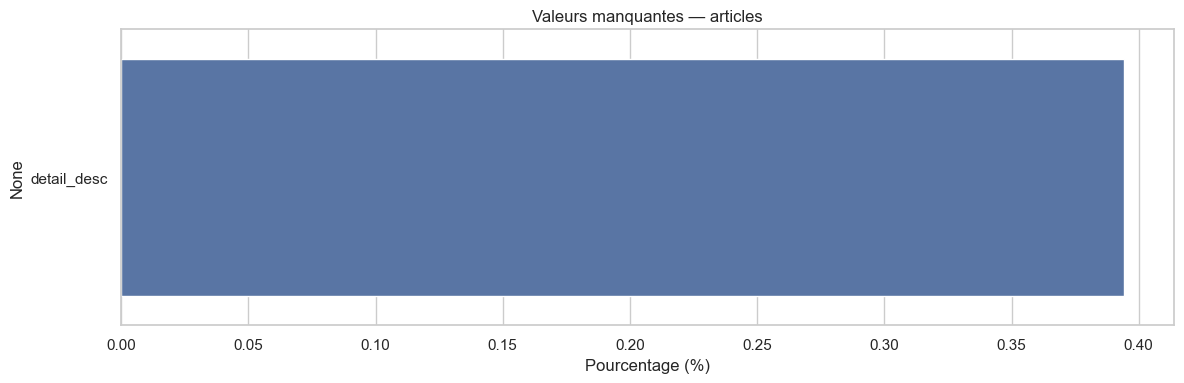

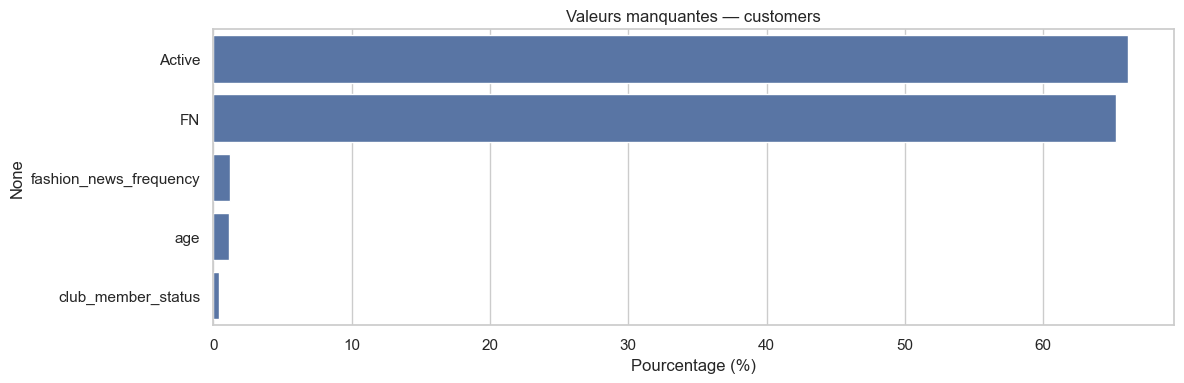

Aucune valeur manquante : transactions


In [7]:
def plot_missing(df, title):
    missing = (df.isna().mean() * 100).sort_values(ascending=False)
    missing = missing[missing > 0]
    if missing.empty:
        print("Aucune valeur manquante :", title)
        return
    plt.figure(figsize=(12, max(4, len(missing) * 0.3)))
    sns.barplot(x=missing.values, y=missing.index)
    plt.title("Valeurs manquantes — " + title)
    plt.xlabel("Pourcentage (%)")
    plt.tight_layout()
    plt.show()

plot_missing(articles, "articles")
plot_missing(customers, "customers")
plot_missing(transactions, "transactions")

## 6. Vérification des identifiants et de la cohérence des tables

In [8]:
expected = {
    "articles": (articles, ["article_id"]),
    "customers": (customers, ["customer_id"]),
    "transactions": (transactions, ["customer_id", "article_id", "t_dat", "price", "sales_channel_id"])
}
for name, (df, cols) in expected.items():
    absent = [c for c in cols if c not in df.columns]
    print(name, "— colonnes absentes :", absent if absent else "aucune")

if "article_id" in articles:
    print("IDs article dupliqués :", articles["article_id"].duplicated().sum())
if "customer_id" in customers:
    print("IDs client dupliqués :", customers["customer_id"].duplicated().sum())

articles — colonnes absentes : aucune
customers — colonnes absentes : aucune
transactions — colonnes absentes : aucune
IDs article dupliqués : 0
IDs client dupliqués : 0


## 7. Analyse exploratoire des données (EDA)

### 7.1 Répartition des clients selon l’âge

In [ ]:
if "age" in customers.columns:
    age = pd.to_numeric(customers["age"], errors="coerce")
    display(age.describe())
    plt.figure(figsize=(9, 4))
    sns.histplot(age.dropna(), bins=40, kde=True)
    plt.title("Distribution de l'âge des clients")
    plt.xlabel("Âge")
    plt.ylabel("Nombre de clients")
    plt.show()
else:
    print("Colonne age absente.")

### 7.2 Répartition des statuts clients et des préférences de communication

In [9]:
for col in ["club_member_status", "fashion_news_frequency", "FN", "Active"]:
    if col in customers.columns:
        print("\nRépartition :", col)
        display(customers[col].value_counts(dropna=False).to_frame("effectif"))


Répartition : club_member_status


,effectif
club_member_status,
ACTIVE,1272491
PRE-CREATE,92960
NaN,6062
LEFT CLUB,467



Répartition : fashion_news_frequency


,effectif
fashion_news_frequency,
NONE,877711
Regularly,477416
NaN,16011
Monthly,842



Répartition : FN


,effectif
FN,
NaN,895050
1.0,476930



Répartition : Active


,effectif
Active,
NaN,907576
1.0,464404


### 7.3 Étude de la distribution des prix

count    100000.000000
mean          0.029593
std           0.022437
min           0.000797
1%            0.005068
25%           0.016932
50%           0.025407
75%           0.033881
99%           0.118627
max           0.591525
Name: price, dtype: float64

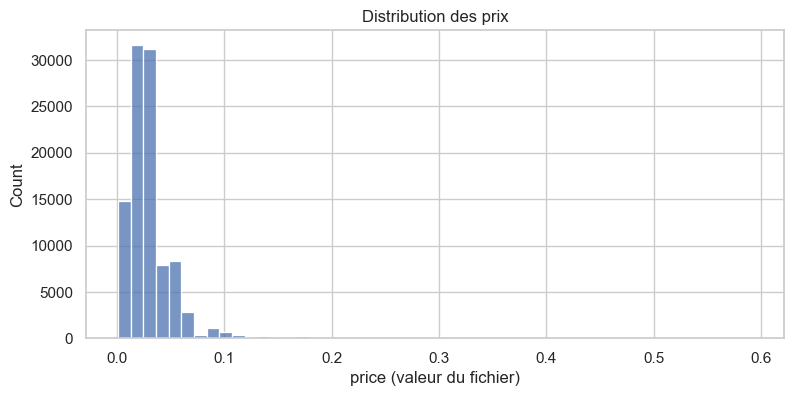

In [10]:
if "price" in transactions.columns:
    price = pd.to_numeric(transactions["price"], errors="coerce")
    display(price.describe(percentiles=[.01, .25, .5, .75, .99]))
    plt.figure(figsize=(9, 4))
    sns.histplot(price.dropna(), bins=50)
    plt.title("Distribution des prix")
    plt.xlabel("price (valeur du fichier)")
    plt.show()

### 7.4 Évolution du volume des transactions dans le temps

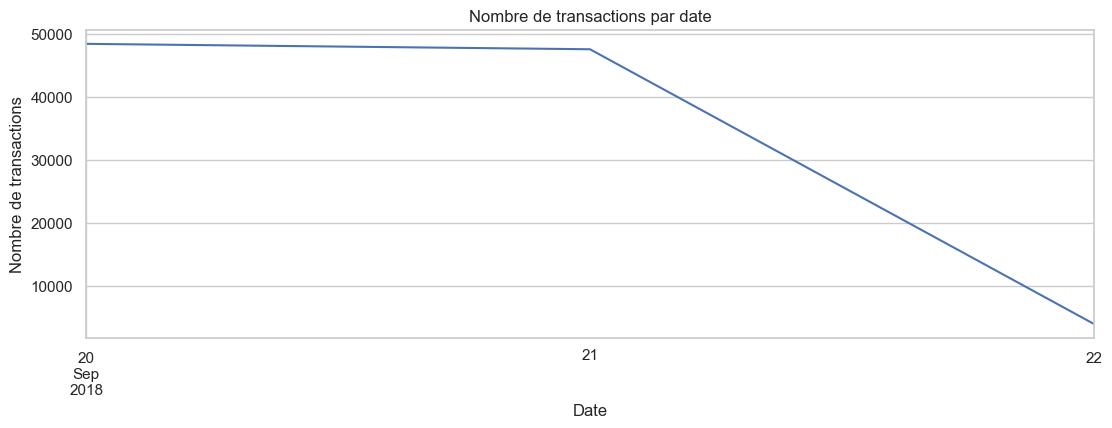

Période : 2018-09-20 00:00:00 à 2018-09-22 00:00:00


In [11]:
if "t_dat" in transactions.columns:
    dates = pd.to_datetime(transactions["t_dat"], errors="coerce")
    daily = dates.dropna().value_counts().sort_index()
    if not daily.empty:
        plt.figure(figsize=(13, 4))
        daily.plot()
        plt.title("Nombre de transactions par date")
        plt.xlabel("Date")
        plt.ylabel("Nombre de transactions")
        plt.show()
        print("Période :", dates.min(), "à", dates.max())

### 7.5 Identification des articles les plus achetés

,nombre_transactions
article_id,
685687004,797
685687001,526
685687003,438
685687002,288
562245001,275
673677002,267
671505002,217
683662005,210
573085001,208


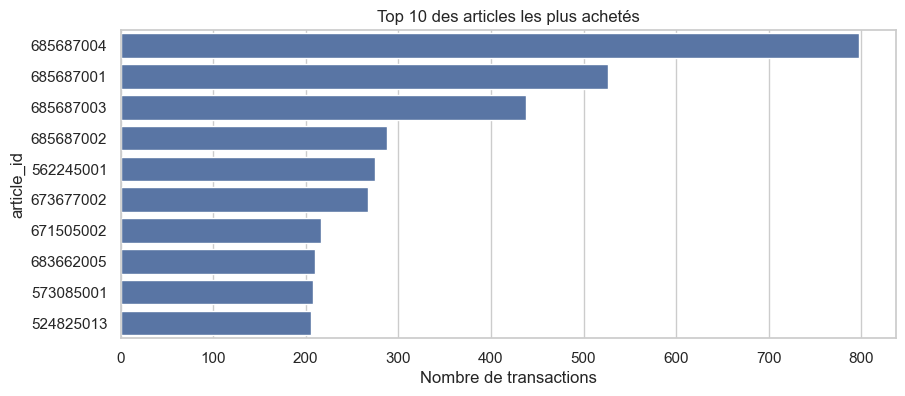

In [12]:
if "article_id" in transactions.columns:
    top = transactions["article_id"].value_counts().head(10)
    display(top.to_frame("nombre_transactions"))
    plt.figure(figsize=(10, 4))
    sns.barplot(x=top.values, y=top.index.astype(str))
    plt.title("Top 10 des articles les plus achetés")
    plt.xlabel("Nombre de transactions")
    plt.ylabel("article_id")
    plt.show()

### 7.6 Analyse de la fréquence d’achat par client

count    28317.000000
mean         3.531448
std          3.703526
min          1.000000
25%          1.000000
50%          2.000000
75%          4.000000
max        103.000000
dtype: float64

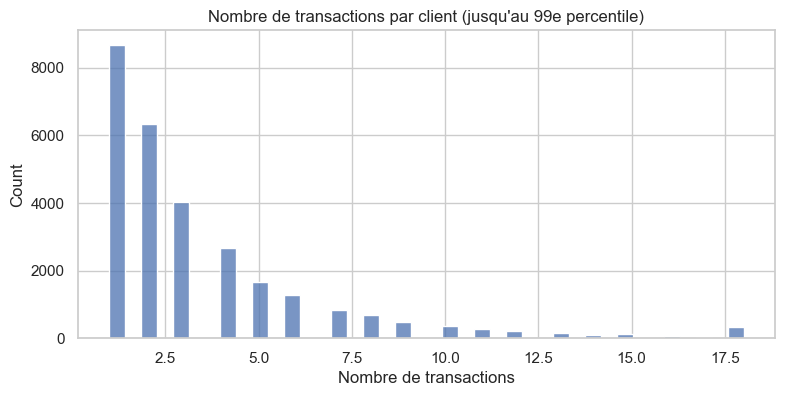

In [13]:
if "customer_id" in transactions.columns:
    per_customer = transactions.groupby("customer_id").size()
    display(per_customer.describe())
    plt.figure(figsize=(9, 4))
    sns.histplot(per_customer.clip(upper=per_customer.quantile(.99)), bins=40)
    plt.title("Nombre de transactions par client (jusqu'au 99e percentile)")
    plt.xlabel("Nombre de transactions")
    plt.show()

### 7.7 Analyse des catégories de produits achetées

,nombre_transactions
product_group_name,
Garment Upper body,48166
Garment Lower body,24598
Garment Full body,7204
Underwear,6629
Accessories,4657
Swimwear,2660
Shoes,2571
Socks & Tights,2446
Nightwear,988


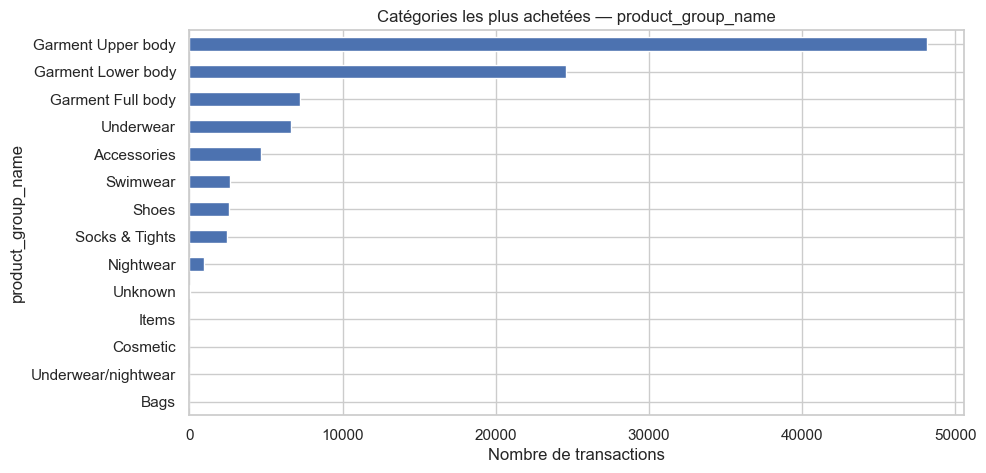

In [14]:
if "article_id" in transactions.columns and "article_id" in articles.columns:
    category_cols = ["product_group_name", "product_type_name", "index_group_name", "colour_group_name"]
    available = [c for c in category_cols if c in articles.columns]
    if available:
        category_col = "product_group_name" if "product_group_name" in available else available[0]
        ref = articles[["article_id", category_col]].drop_duplicates("article_id")
        tx_cat = transactions[["article_id"]].merge(
            ref, on="article_id", how="left", validate="many_to_one"
        )
        counts = tx_cat[category_col].value_counts(dropna=False).head(15)
        display(counts.to_frame("nombre_transactions"))
        counts.sort_values().plot(kind="barh", figsize=(10, 5))
        plt.title("Catégories les plus achetées — " + category_col)
        plt.xlabel("Nombre de transactions")
        plt.show()
    else:
        print("Aucune colonne de catégorie connue n'est disponible.")

## 8. Nettoyage et préparation des données transactionnelles

> **Point de vigilance :** l’exécution actuelle détecte 9 500 lignes identiques parmi les 100 000 lignes chargées. Avant de les supprimer, il faut vérifier si elles correspondent à des doublons techniques ou à des achats répétés légitimes. La suppression automatique peut modifier les fréquences d’interaction utilisées par le modèle.

In [15]:
tx = transactions.copy()
art = articles.copy()
cust = customers.copy()

if "t_dat" in tx.columns:
    tx["t_dat"] = pd.to_datetime(tx["t_dat"], errors="coerce")

before = len(tx)
tx = tx.drop_duplicates().copy()
print("Doublons exacts supprimés :", before - len(tx))

key_cols = [c for c in ["customer_id", "article_id"] if c in tx.columns]
before = len(tx)
tx = tx.dropna(subset=key_cols).copy()
print("Lignes supprimées pour clé manquante :", before - len(tx))

if "t_dat" in tx.columns:
    print("Dates invalides :", tx["t_dat"].isna().sum())

if "price" in tx.columns:
    tx["price"] = pd.to_numeric(tx["price"], errors="coerce")
    print("Prix manquants :", tx["price"].isna().sum())
    print("Prix <= 0 :", (tx["price"] <= 0).sum())
    print("Prix > 1 :", (tx["price"] > 1).sum())

print("Transactions après nettoyage prudent :", tx.shape)

Doublons exacts supprimés : 9500
Lignes supprimées pour clé manquante : 0
Dates invalides : 0
Prix manquants : 0
Prix <= 0 : 0
Prix > 1 : 0
Transactions après nettoyage prudent : (90500, 5)


### 8.1 Vérification de l’unicité des identifiants avant les jointures

In [16]:
print("Doublons article_id :", art["article_id"].duplicated().sum())
print("Doublons customer_id :", cust["customer_id"].duplicated().sum())

assert not art["article_id"].duplicated().any(), (
    "article_id dupliqué dans articles.csv : examiner avant jointure."
)
assert not cust["customer_id"].duplicated().any(), (
    "customer_id dupliqué dans customers.csv : examiner avant jointure."
)

Doublons article_id : 0
Doublons customer_id : 0


## 9. Construction de la table des interactions client–article

In [17]:
interaction_cols = [
    c for c in ["customer_id", "article_id", "t_dat", "price", "sales_channel_id"]
    if c in tx.columns
]
interactions = tx[interaction_cols].copy()

print("Dimensions :", interactions.shape)
print("Clients distincts :", interactions["customer_id"].nunique())
print("Articles distincts :", interactions["article_id"].nunique())
display(interactions.head())

Dimensions : (90500, 5)
Clients distincts : 28317
Articles distincts : 15581


,customer_id,article_id,t_dat,price,sales_channel_id
0,000058a12d5b43e67d225668fa1f8d618c13dc232df0cad8ffe7ad4a1091e318,663713001,2018-09-20,0.050831,2
1,000058a12d5b43e67d225668fa1f8d618c13dc232df0cad8ffe7ad4a1091e318,541518023,2018-09-20,0.030492,2
2,00007d2de826758b65a93dd24ce629ed66842531df6699338c5570910a014cc2,505221004,2018-09-20,0.015237,2
3,00007d2de826758b65a93dd24ce629ed66842531df6699338c5570910a014cc2,685687003,2018-09-20,0.016932,2
4,00007d2de826758b65a93dd24ce629ed66842531df6699338c5570910a014cc2,685687004,2018-09-20,0.016932,2


### 9.1 Agrégation des interactions par client et par article

In [18]:
interaction_counts = (
    interactions.groupby(["customer_id", "article_id"], as_index=False)
    .size()
    .rename(columns={"size": "interaction_count"})
)
display(interaction_counts.head())
print("Couples client-article :", len(interaction_counts))

,customer_id,article_id,interaction_count
0,0000423b00ade91418cceaf3b26c6af3dd342b51fd051eec9c12fb36984420fa,583558001,1
1,0000423b00ade91418cceaf3b26c6af3dd342b51fd051eec9c12fb36984420fa,639677008,1
2,0000423b00ade91418cceaf3b26c6af3dd342b51fd051eec9c12fb36984420fa,640244003,1
3,000058a12d5b43e67d225668fa1f8d618c13dc232df0cad8ffe7ad4a1091e318,541518023,1
4,000058a12d5b43e67d225668fa1f8d618c13dc232df0cad8ffe7ad4a1091e318,663713001,1


Couples client-article : 89902


## 10. Enrichissement des interactions avec les données clients et articles

In [19]:
ml_dataset = interactions.merge(
    art, on="article_id", how="left",
    validate="many_to_one", suffixes=("", "_article")
)
ml_dataset = ml_dataset.merge(
    cust, on="customer_id", how="left",
    validate="many_to_one", suffixes=("", "_customer")
)

print("Dimensions après fusion :", ml_dataset.shape)
display(ml_dataset.head())

Dimensions après fusion : (90500, 35)


,customer_id,article_id,t_dat,price,sales_channel_id,product_code,prod_name,product_type_no,product_type_name,product_group_name,graphical_appearance_no,graphical_appearance_name,colour_group_code,colour_group_name,perceived_colour_value_id,perceived_colour_value_name,perceived_colour_master_id,perceived_colour_master_name,department_no,department_name,index_code,index_name,index_group_no,index_group_name,section_no,section_name,garment_group_no,garment_group_name,detail_desc,FN,Active,club_member_status,fashion_news_frequency,age,postal_code
0,000058a12d5b43e67d225668fa1f8d618c13dc232df0cad8ffe7ad4a1091e318,663713001,2018-09-20,0.050831,2,663713,Atlanta Push Body Harlow,283,Underwear body,Underwear,1010016,Solid,9,Black,4,Dark,5,Black,1338,Expressive Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Lace push-up body with underwired, moulded, padded cups for a larger bust and fuller cleavage. N...",NaN,NaN,ACTIVE,NONE,24.0,64f17e6a330a85798e4998f62d0930d14db8db1c054af6c9090f7dd3e38380dc
1,000058a12d5b43e67d225668fa1f8d618c13dc232df0cad8ffe7ad4a1091e318,541518023,2018-09-20,0.030492,2,541518,Rae Push (Melbourne) 2p,306,Bra,Underwear,1010016,Solid,51,Light Pink,1,Dusty Light,4,Pink,1334,Casual Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Lace push-up bras with underwired, moulded, padded cups for a larger bust and fuller cleavage. A...",NaN,NaN,ACTIVE,NONE,24.0,64f17e6a330a85798e4998f62d0930d14db8db1c054af6c9090f7dd3e38380dc
2,00007d2de826758b65a93dd24ce629ed66842531df6699338c5570910a014cc2,505221004,2018-09-20,0.015237,2,505221,Inca Jumper,252,Sweater,Garment Upper body,1010010,Melange,52,Pink,2,Medium Dusty,4,Pink,5963,Tops Knitwear DS,D,Divided,2,Divided,58,Divided Selected,1003,Knitwear,"Jumper in rib-knit cotton with hard-worn details, a wide, roll-edge neckline, and gently dropped...",1.0,1.0,ACTIVE,Regularly,32.0,8d6f45050876d059c830a0fe63f1a4c022de279bb68ce312615afb86814fec7a
3,00007d2de826758b65a93dd24ce629ed66842531df6699338c5570910a014cc2,685687003,2018-09-20,0.016932,2,685687,W YODA KNIT OL OFFER,252,Sweater,Garment Upper body,1010010,Melange,52,Pink,7,Medium,4,Pink,3090,Campaigns,A,Ladieswear,1,Ladieswear,15,Womens Everyday Collection,1023,Special Offers,"V-neck knitted jumper with long sleeves and ribbing around the neckline, cuffs and hem.",1.0,1.0,ACTIVE,Regularly,32.0,8d6f45050876d059c830a0fe63f1a4c022de279bb68ce312615afb86814fec7a
4,00007d2de826758b65a93dd24ce629ed66842531df6699338c5570910a014cc2,685687004,2018-09-20,0.016932,2,685687,W YODA KNIT OL OFFER,252,Sweater,Garment Upper body,1010010,Melange,93,Dark Green,4,Dark,19,Green,3090,Campaigns,A,Ladieswear,1,Ladieswear,15,Womens Everyday Collection,1023,Special Offers,"V-neck knitted jumper with long sleeves and ribbing around the neckline, cuffs and hem.",1.0,1.0,ACTIVE,Regularly,32.0,8d6f45050876d059c830a0fe63f1a4c022de279bb68ce312615afb86814fec7a


### 10.1 Évaluation de la couverture des jointures

In [20]:
article_col = next(
    (c for c in ["prod_name", "product_type_name", "product_group_name"] if c in ml_dataset.columns),
    None
)
customer_col = next(
    (c for c in ["age", "club_member_status", "fashion_news_frequency"] if c in ml_dataset.columns),
    None
)

if article_col:
    print("Couverture articles :", round(ml_dataset[article_col].notna().mean() * 100, 2), "%")
else:
    print("Pas de colonne descriptive article disponible pour ce contrôle.")

if customer_col:
    print("Couverture clients :", round(ml_dataset[customer_col].notna().mean() * 100, 2), "%")
else:
    print("Pas de colonne descriptive client disponible pour ce contrôle.")

Couverture articles : 100.0 %
Couverture clients : 99.43 %


## 11. Sélection des variables candidates pour le modèle

In [21]:
candidate_features = [
    "customer_id", "article_id", "t_dat", "price", "sales_channel_id",
    "age", "club_member_status", "fashion_news_frequency",
    "product_type_name", "product_group_name", "colour_group_name", "index_group_name"
]
selected = [c for c in candidate_features if c in ml_dataset.columns]
not_found = [c for c in candidate_features if c not in ml_dataset.columns]

print("Variables candidates disponibles :", selected)
print("Variables non présentes :", not_found)

candidate_dataset = ml_dataset[selected].copy()
display(candidate_dataset.head())
display(pd.DataFrame({
    "manquants": candidate_dataset.isna().sum(),
    "manquants_%": (candidate_dataset.isna().mean() * 100).round(2)
}))

Variables candidates disponibles : ['customer_id', 'article_id', 't_dat', 'price', 'sales_channel_id', 'age', 'club_member_status', 'fashion_news_frequency', 'product_type_name', 'product_group_name', 'colour_group_name', 'index_group_name']
Variables non présentes : []


,customer_id,article_id,t_dat,price,sales_channel_id,age,club_member_status,fashion_news_frequency,product_type_name,product_group_name,colour_group_name,index_group_name
0,000058a12d5b43e67d225668fa1f8d618c13dc232df0cad8ffe7ad4a1091e318,663713001,2018-09-20,0.050831,2,24.0,ACTIVE,NONE,Underwear body,Underwear,Black,Ladieswear
1,000058a12d5b43e67d225668fa1f8d618c13dc232df0cad8ffe7ad4a1091e318,541518023,2018-09-20,0.030492,2,24.0,ACTIVE,NONE,Bra,Underwear,Light Pink,Ladieswear
2,00007d2de826758b65a93dd24ce629ed66842531df6699338c5570910a014cc2,505221004,2018-09-20,0.015237,2,32.0,ACTIVE,Regularly,Sweater,Garment Upper body,Pink,Divided
3,00007d2de826758b65a93dd24ce629ed66842531df6699338c5570910a014cc2,685687003,2018-09-20,0.016932,2,32.0,ACTIVE,Regularly,Sweater,Garment Upper body,Pink,Ladieswear
4,00007d2de826758b65a93dd24ce629ed66842531df6699338c5570910a014cc2,685687004,2018-09-20,0.016932,2,32.0,ACTIVE,Regularly,Sweater,Garment Upper body,Dark Green,Ladieswear


,manquants,manquants_%
customer_id,0,0.00
article_id,0,0.00
t_dat,0,0.00
price,0,0.00
sales_channel_id,0,0.00
age,518,0.57
club_member_status,957,1.06
fashion_news_frequency,408,0.45
product_type_name,0,0.00
product_group_name,0,0.00


## 12. Encodage des identifiants clients et articles

In [22]:
customer_mapping = pd.DataFrame({
    "customer_id": interactions["customer_id"].dropna().drop_duplicates().reset_index(drop=True)
})
customer_mapping["user_idx"] = np.arange(len(customer_mapping))

article_mapping = pd.DataFrame({
    "article_id": interactions["article_id"].dropna().drop_duplicates().reset_index(drop=True)
})
article_mapping["item_idx"] = np.arange(len(article_mapping))

display(customer_mapping.head())
display(article_mapping.head())

,customer_id,user_idx
0,000058a12d5b43e67d225668fa1f8d618c13dc232df0cad8ffe7ad4a1091e318,0
1,00007d2de826758b65a93dd24ce629ed66842531df6699338c5570910a014cc2,1
2,00083cda041544b2fbb0e0d2905ad17da7cf1007526fb4c73235dccbbc132280,2
3,0008968c0d451dbc5a9968da03196fe20051965edde7413775c4eb3be9abe9c2,3
4,000aa7f0dc06cd7174389e76c9e132a67860c5f65f970699daccc14425ac31a8,4


,article_id,item_idx
0,663713001,0
1,541518023,1
2,505221004,2
3,685687003,3
4,685687004,4


## 13. Vérifications finales du jeu de données préparé

In [23]:
assert interactions["customer_id"].notna().all()
assert interactions["article_id"].notna().all()

print("Interactions :", len(interactions))
print("Clients distincts :", interactions["customer_id"].nunique())
print("Articles distincts :", interactions["article_id"].nunique())
print("Couples client-article distincts :", len(interaction_counts))
print("Doublons exacts dans interactions :", interactions.duplicated().sum())

display(pd.DataFrame({
    "table": ["interactions", "interaction_counts", "candidate_dataset", "ml_dataset"],
    "lignes": [len(interactions), len(interaction_counts), len(candidate_dataset), len(ml_dataset)],
    "colonnes": [interactions.shape[1], interaction_counts.shape[1],
                 candidate_dataset.shape[1], ml_dataset.shape[1]]
}))

Interactions : 90500
Clients distincts : 28317
Articles distincts : 15581
Couples client-article distincts : 89902
Doublons exacts dans interactions : 0


,table,lignes,colonnes
0,interactions,90500,5
1,interaction_counts,89902,3
2,candidate_dataset,90500,12
3,ml_dataset,90500,35


In [24]:
interactions.to_parquet(OUTPUT_DIR / "ml_interactions.parquet", index=False)
interaction_counts.to_parquet(OUTPUT_DIR / "ml_interaction_counts.parquet", index=False)
candidate_dataset.to_parquet(OUTPUT_DIR / "ml_candidate_features.parquet", index=False)
ml_dataset.to_parquet(OUTPUT_DIR / "ml_dataset_enriched.parquet", index=False)

customer_mapping.to_csv(OUTPUT_DIR / "customer_mapping.csv", index=False)
article_mapping.to_csv(OUTPUT_DIR / "article_mapping.csv", index=False)

print("Fichiers exportés dans :", OUTPUT_DIR.resolve())

Fichiers exportés dans : C:\Users\CYBORG\VogueMind\data\processed


In [25]:
check_interactions = pd.read_parquet(OUTPUT_DIR / "ml_interactions.parquet")
check_dataset = pd.read_parquet(OUTPUT_DIR / "ml_dataset_enriched.parquet")

print("Interactions exportées :", check_interactions.shape)
print("Dataset enrichi exporté :", check_dataset.shape)

assert check_interactions.shape == interactions.shape
assert check_dataset.shape == ml_dataset.shape
print("Vérification de relecture : OK")

Interactions exportées : (90500, 5)
Dataset enrichi exporté : (90500, 35)
Vérification de relecture : OK


## 14. Exportation et sauvegarde des données préparées

In [26]:
summary = {
    "transactions_chargees": int(len(transactions)),
    "fichier_transactions_complet": bool(LOAD_FULL_TRANSACTIONS),
    "articles_lignes": int(len(articles)),
    "clients_lignes": int(len(customers)),
    "transactions_apres_nettoyage": int(len(tx)),
    "interactions_exportees": int(len(interactions)),
    "clients_distincts": int(interactions["customer_id"].nunique()),
    "articles_distincts": int(interactions["article_id"].nunique()),
    "couples_client_article": int(len(interaction_counts)),
    "dataset_enrichi_lignes": int(len(ml_dataset)),
    "dataset_enrichi_colonnes": int(ml_dataset.shape[1])
}

summary_df = pd.DataFrame([{"indicateur": k, "valeur": v} for k, v in summary.items()])
display(summary_df)
summary_df.to_csv(OUTPUT_DIR / "preparation_summary.csv", index=False)

with open(OUTPUT_DIR / "preparation_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=4)

print("Résumé enregistré.")

,indicateur,valeur
0,transactions_chargees,100000
1,fichier_transactions_complet,False
2,articles_lignes,105542
3,clients_lignes,1371980
4,transactions_apres_nettoyage,90500
5,interactions_exportees,90500
6,clients_distincts,28317
7,articles_distincts,15581
8,couples_client_article,89902
9,dataset_enrichi_lignes,90500


Résumé enregistré.


## 15. Synthèse des résultats et bilan du travail

> Cette étape constitue la préparation des données en amont du modèle. La sélection définitive des variables, la stratégie de séparation temporelle et le format attendu doivent être validés avec la personne chargée de l’entraînement.